# Compressed sensing in pictures

Before any theorem, the whole subject fits in a handful of matrix pictures.
This notebook draws the measurement model of compressed sensing (CS) block
by block, so you can see which quantities are short, which are long, and
which are sparse. It then shows what the basis $\boldsymbol{\Psi}$ and the
coefficients $\boldsymbol{s}$ look like for a real 1-D signal and for an
image.

**In this notebook you will**

* see why $\boldsymbol{y}=\mathbf{C}\boldsymbol{x}$ with fewer measurements
  than unknowns needs a sparsity prior;
* follow the change of unknown
  $\boldsymbol{x}=\boldsymbol{\Psi}\boldsymbol{s}$ that turns a dense signal
  into a sparse coefficient vector, and the collapsed sensing matrix
  $\boldsymbol{\Phi}=\mathbf{C}\boldsymbol{\Psi}$;
* check that a three-tone signal is exactly 6-sparse in the Fourier basis;
* see how an image is turned into a vector, and that 20% of its 2-D Fourier
  coefficients are enough to keep the picture.

**Before this notebook:** `cs_sparsity` (sparse and compressible signals).
**Next:** `cs_regularization` (why the $\ell_1$ norm finds sparse
solutions).

**Runtime:** a few seconds on a laptop.

### The model

We want a signal $\boldsymbol{x}\in\mathbb{R}^n$ but can only afford
$m\ll n$ measurements, collected in $\boldsymbol{y}\in\mathbb{R}^m$:

$$\boldsymbol{y}=\mathbf{C}\boldsymbol{x},\qquad
  \mathbf{C}\in\mathbb{R}^{m\times n}.$$

Each row of the measurement matrix $\mathbf{C}$ says how one measurement
mixes the entries of $\boldsymbol{x}$. With $m<n$ the system has fewer
equations than unknowns (it is *underdetermined*), so infinitely many
$\boldsymbol{x}$ fit the data and we need a prior. If $\boldsymbol{x}$ is
itself sparse the prior is direct. If it is dense we change the unknown to
its coefficients $\boldsymbol{s}$ in a basis $\boldsymbol{\Psi}$
($n\times n$, columns are the basis vectors) where it *is* sparse:

$$\boldsymbol{x}=\boldsymbol{\Psi}\boldsymbol{s}
  \quad\Longrightarrow\quad
  \boldsymbol{y}=\mathbf{C}\boldsymbol{\Psi}\boldsymbol{s}
  =\boldsymbol{\Phi}\boldsymbol{s},\qquad
  \|\boldsymbol{s}\|_0=k\ll n .$$

Here $\|\boldsymbol{s}\|_0$ counts the nonzero entries of $\boldsymbol{s}$ and
$\boldsymbol{\Phi}\in\mathbb{R}^{m\times n}$ is the effective sensing matrix.

### Setup

Imports, the course plotting style, and the folders for figures and data.
`save_dual` writes every figure in a light and a dark version.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from PIL import Image
from scipy.fft import idct
from pyutils import set_plot_style, save_dual, fg, muted
set_plot_style()

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
DATA = os.path.abspath(os.path.join('..', 'data'))

## Parameters (edit these)

Every size and setting used below is defined here. The toy system (sections
1 to 3) uses a signal of length $n$ = `N_TOY` with $m$ = `M_TOY`
measurements and a coefficient vector $\boldsymbol{s}$ that is nonzero only
at the indices in `SUPPORT`. Section 4 uses a 1-D signal of `N_SIG` samples
made of the sine waves in `TONES`. Section 5 uses the portrait at two sizes:
`SIDE_PSI` (small enough to draw the full basis matrix) and `SIDE_IMG` (for
the reconstruction). `KEEP_1D` and `KEEP_2D` are the fractions of
coefficients kept when compressing.

In [2]:
SEED = 0
N_TOY, M_TOY = 16, 8            # block pictures: signal length n, measurements m
SUPPORT = [3, 7, 12]            # nonzero entries of the sparse coefficient vector s
N_SIG = 256                     # 1-D signal length
TONES = [(5, 0.7), (12, 0.5), (20, 0.3)]   # (frequency, amplitude) of the 1-D signal
KEEP_1D = 0.05                  # fraction of Fourier coefficients kept (1-D)
SIDE_PSI = 32                   # image side used to *draw* the 2-D basis (n = SIDE_PSI^2)
SIDE_IMG = 128                  # image side used for the reconstruction panel
KEEP_2D = 0.20                  # fraction of 2-D Fourier coefficients kept

rng = np.random.default_rng(SEED)

## 1. The toy system

A real orthonormal basis keeps every picture consistent: $\boldsymbol{\Psi}$
is the $n\times n$ inverse-DCT matrix, so $\boldsymbol{x}=\boldsymbol{\Psi}
\boldsymbol{s}$ is real and $\boldsymbol{y}=\mathbf{C}\boldsymbol{x}
=\boldsymbol{\Phi}\boldsymbol{s}$ holds to machine precision. $\mathbf{C}$ is
Gaussian (independent normal entries scaled by $1/\sqrt{m}$), the generic
"random enough" measurement.

The cell below builds:

* `PSI` $=\boldsymbol{\Psi}$ ($n\times n$): column $j$ is the $j$-th DCT basis
  vector, obtained by applying the inverse DCT to the identity matrix;
* `C` $=\mathbf{C}$ ($m\times n$): the random measurement matrix;
* `s` $=\boldsymbol{s}$: zero except at the three indices in `SUPPORT`;
* `x` $=\boldsymbol{\Psi}\boldsymbol{s}$ (dense), `y` $=\mathbf{C}\boldsymbol{x}$,
  and `PHI` $=\boldsymbol{\Phi}=\mathbf{C}\boldsymbol{\Psi}$;
* `x_sparse`, a second signal that is sparse in the sample domain itself
  (three nonzero entries), and its measurements `y_sparse`.

The asserts check that $\boldsymbol{\Psi}$ is orthonormal
($\boldsymbol{\Psi}^{\top}\boldsymbol{\Psi}=\mathbf{I}$), that the two
ways of computing $\boldsymbol{y}$ agree, that $\boldsymbol{x}$ is dense and
that $\boldsymbol{s}$ has exactly three nonzeros.

In [3]:
n, m = N_TOY, M_TOY
PSI = idct(np.eye(n), norm='ortho', axis=0)          # columns = DCT basis vectors
C = rng.standard_normal((m, n)) / np.sqrt(m)
s = np.zeros(n); s[SUPPORT] = [1.6, -1.0, 1.2]
x = PSI @ s                                          # dense signal
y = C @ x
PHI = C @ PSI

x_sparse = np.zeros(n); x_sparse[[2, 9, 13]] = [1.0, -0.7, 1.3]   # a signal sparse as is
y_sparse = C @ x_sparse

assert np.allclose(PSI.T @ PSI, np.eye(n)), "Psi must be orthonormal"
assert np.allclose(y, PHI @ s), "y = C Psi s = Phi s"
assert np.count_nonzero(np.abs(x) > 1e-12) == n, "x must be dense"
assert np.count_nonzero(s) == len(SUPPORT)
print(f"n={n}, m={m}, ||s||_0={np.count_nonzero(s)}, ||x||_0={np.count_nonzero(np.abs(x)>1e-12)}")

n=16, m=8, ||s||_0=3, ||x||_0=16


The printout confirms the setting: $n=16$ unknowns, $m=8$ measurements, a
coefficient vector with 3 nonzeros, and a signal $\boldsymbol{x}$ with all 16
entries nonzero. Eight equations cannot pin down 16 free numbers, but they
can pin down 3 if we know the answer is sparse.

## 2. Drawing helpers

Vectors are columns of square cells; zero entries are left blank so sparsity
is visible at a glance. Everything is inked with `fg()` so the same function
draws the light (print) and dark (slides) variants.

* `draw_vector` draws a column of cells, coloured with the `plasma` map;
* `draw_matrix` draws a coloured block (`viridis` for $\mathbf{C}$,
  `coolwarm` for the bases, red positive and blue negative), or only its
  outline when `draw=False`;
* the `NORM_*` objects fix one symmetric colour scale per quantity, so the
  same vector keeps the same colours from picture to picture.

This cell only defines functions; it draws nothing.

In [4]:
VEC_CMAP, C_CMAP, BASIS_CMAP = 'plasma', 'viridis', 'coolwarm'


def draw_vector(ax, v, x0, y0, label, dims, cmap=VEC_CMAP, norm=None, blank_zeros=True):
    v = np.asarray(v, float); k = len(v)
    vals = np.ma.masked_where(np.abs(v) < 1e-12, v) if blank_zeros else v
    if norm is None:
        lim = np.max(np.abs(v)) if np.any(v) else 1.0
        norm = Normalize(-lim, lim)
    if np.any(np.abs(v) > 1e-12) or not blank_zeros:
        ax.imshow(vals.reshape(k, 1), cmap=cmap, norm=norm, aspect='auto',
                  extent=[x0, x0 + 1, y0, y0 + k], interpolation='nearest')
    for i in range(k + 1):
        ax.plot([x0, x0 + 1], [y0 + i, y0 + i], color=fg(), lw=0.6)
    ax.plot([x0, x0 + 1, x0 + 1, x0, x0], [y0, y0, y0 + k, y0 + k, y0], color=fg(), lw=1.1)
    ax.text(x0 + 0.5, y0 + k + 0.9, label, ha='center', fontsize=17)
    ax.text(x0 + 0.5, y0 - 1.3, dims, ha='center', fontsize=12)


def draw_matrix(ax, M, x0, y0, label, dims, cmap=C_CMAP, norm=None, draw=True):
    r, c = M.shape
    if draw:
        if norm is None:
            lim = np.max(np.abs(M)); norm = Normalize(-lim, lim)
        ax.imshow(M, cmap=cmap, norm=norm, aspect='auto',
                  extent=[x0, x0 + c, y0, y0 + r], interpolation='nearest')
    ax.plot([x0, x0 + c, x0 + c, x0, x0], [y0, y0, y0 + r, y0 + r, y0], color=fg(), lw=1.1)
    ax.text(x0 + c / 2, y0 + r + 0.9, label, ha='center', fontsize=17)
    ax.text(x0 + c / 2, y0 - 1.3, dims, ha='center', fontsize=12)


def equals(ax, xc, yc):
    ax.text(xc, yc, '$=$', ha='center', va='center', fontsize=22)


def finish(ax):
    ax.set_aspect('equal'); ax.axis('off')


# shared colour scales so y, x and s keep their colours from picture to picture
NORM_Y = Normalize(-np.max(np.abs(np.r_[y, y_sparse])), np.max(np.abs(np.r_[y, y_sparse])))
NORM_X = Normalize(-np.max(np.abs(x)), np.max(np.abs(x)))
NORM_S = Normalize(-np.max(np.abs(s)), np.max(np.abs(s)))
NORM_PSI = Normalize(-np.max(np.abs(PSI)), np.max(np.abs(PSI)))

Y_LBL, X_LBL, S_LBL = r'$\boldsymbol{y}$', r'$\boldsymbol{x}$', r'$\boldsymbol{s}$'
C_LBL, PSI_LBL, PHI_LBL = r'$\mathbf{C}$', r'$\boldsymbol{\Psi}$', r'$\boldsymbol{\Phi}$'

## 3. The six pictures

(a) the problem; (b) a sparse $\boldsymbol{x}$; (c) a dense one;
(d) the change of basis; (e) the chain $\mathbf{C}\boldsymbol{\Psi}$;
(f) the collapsed system $\boldsymbol{\Phi}\boldsymbol{s}$.

The next cell defines one plotting function per picture. Each picture is
then drawn in its own cell so it can be explained right after.

Common legend for all six: each small square is one number. In vectors the
`plasma` colours run from dark purple (most negative) through orange to
yellow (most positive); a blank white square is an exact zero. In
$\mathbf{C}$ the `viridis` colours run from dark blue (negative) to yellow
(positive). In $\boldsymbol{\Psi}$ and $\boldsymbol{\Phi}$ red is positive,
blue is negative and pale is near zero. The size of each block is written
under it.

In [5]:
def plot_block_problem():
    fig, ax = plt.subplots(figsize=(7, 5))
    draw_vector(ax, np.zeros(m), 0, n - m, Y_LBL, r'$m\times 1$')
    equals(ax, 1.8, n - m / 2)
    draw_matrix(ax, np.zeros((m, n)), 2.5, n - m, C_LBL, r'$m\times n$', draw=False)
    draw_vector(ax, np.zeros(n), 3 + n, 0, X_LBL, r'$n\times 1$')
    finish(ax)


def plot_block_sparse():
    fig, ax = plt.subplots(figsize=(7, 5))
    draw_vector(ax, y_sparse, 0, n - m, Y_LBL, r'$m\times 1$', norm=NORM_Y)
    equals(ax, 1.8, n - m / 2)
    draw_matrix(ax, C, 2.5, n - m, C_LBL, r'$m\times n$')
    draw_vector(ax, x_sparse, 3 + n, 0, X_LBL, r'$n\times 1$', norm=NORM_X)
    finish(ax)


def plot_block_dense():
    fig, ax = plt.subplots(figsize=(7, 5))
    draw_vector(ax, y, 0, n - m, Y_LBL, r'$m\times 1$', norm=NORM_Y)
    equals(ax, 1.8, n - m / 2)
    draw_matrix(ax, C, 2.5, n - m, C_LBL, r'$m\times n$')
    draw_vector(ax, x, 3 + n, 0, X_LBL, r'$n\times 1$', norm=NORM_X)
    finish(ax)


def plot_block_basis():
    fig, ax = plt.subplots(figsize=(7, 5))
    draw_vector(ax, x, 0, 0, X_LBL, r'$n\times 1$', norm=NORM_X)
    equals(ax, 1.8, n / 2)
    draw_matrix(ax, PSI, 2.5, 0, PSI_LBL, r'$n\times n$', cmap=BASIS_CMAP, norm=NORM_PSI)
    draw_vector(ax, s, 3 + n, 0, S_LBL, r'$n\times 1$', norm=NORM_S)
    finish(ax)


def plot_block_chain():
    gap = 1.2
    fig, ax = plt.subplots(figsize=(10, 5))
    draw_vector(ax, y, 0, n - m, Y_LBL, r'$m\times 1$', norm=NORM_Y)
    equals(ax, 1.8, n - m / 2)
    draw_matrix(ax, C, 2.5, n - m, C_LBL, r'$m\times n$')
    draw_matrix(ax, PSI, 2.5 + n + gap, 0, PSI_LBL, r'$n\times n$', cmap=BASIS_CMAP, norm=NORM_PSI)
    draw_vector(ax, s, 2.5 + 2 * n + 2 * gap, 0, S_LBL, r'$n\times 1$', norm=NORM_S)
    finish(ax)


def plot_block_phi():
    fig, ax = plt.subplots(figsize=(7, 5))
    draw_vector(ax, y, 0, n - m, Y_LBL, r'$m\times 1$', norm=NORM_Y)
    equals(ax, 1.8, n - m / 2)
    draw_matrix(ax, PHI, 2.5, n - m, PHI_LBL, r'$m\times n$', cmap=BASIS_CMAP)
    draw_vector(ax, s, 3 + n, 0, S_LBL, r'$n\times 1$', norm=NORM_S)
    finish(ax)

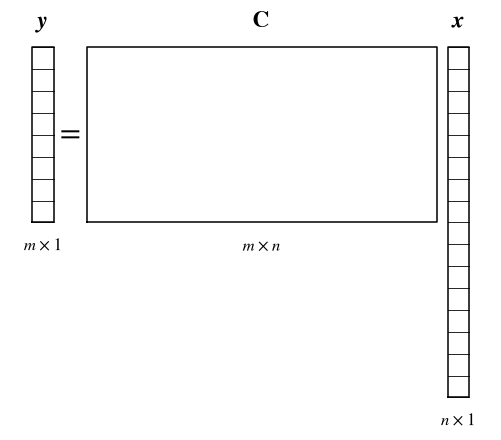

In [6]:
save_dual(plot_block_problem, 'cs_block_problem', FIG)
plt.show()

**How to read this figure.** Picture (a) shows only shapes: the short
column $\boldsymbol{y}$ ($8\times1$), the wide matrix $\mathbf{C}$
($8\times16$) and the long column $\boldsymbol{x}$ ($16\times1$). No values
are drawn.

**What it shows.** The data vector is half as long as the unknown. The
matrix is wider than it is tall, so it has a null space: many different
$\boldsymbol{x}$ produce the same $\boldsymbol{y}$. Without extra
information the problem has no unique answer.

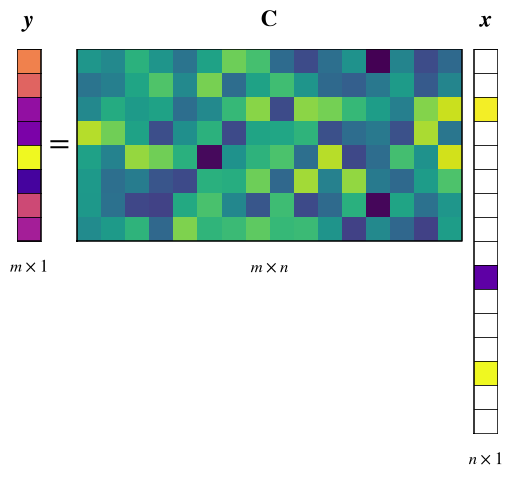

In [7]:
save_dual(plot_block_sparse, 'cs_block_sparse', FIG)
plt.show()

**How to read this figure.** Picture (b) fills in the numbers. $\mathbf{C}$
is the $8\times16$ Gaussian matrix (viridis colours). $\boldsymbol{x}$ is
`x_sparse`: 13 of its 16 cells are blank (zero) and 3 are coloured.
$\boldsymbol{y}$ is the result of the product: 8 coloured cells.

**What it shows.** Even though $\boldsymbol{x}$ has 3 nonzeros, every
measurement in $\boldsymbol{y}$ is nonzero, because each row of $\mathbf{C}$
mixes all entries. If we knew the 3 positions we would have 8 equations in
3 unknowns, which is easy. CS must also find the positions, and this
sparse case is the one it handles directly.

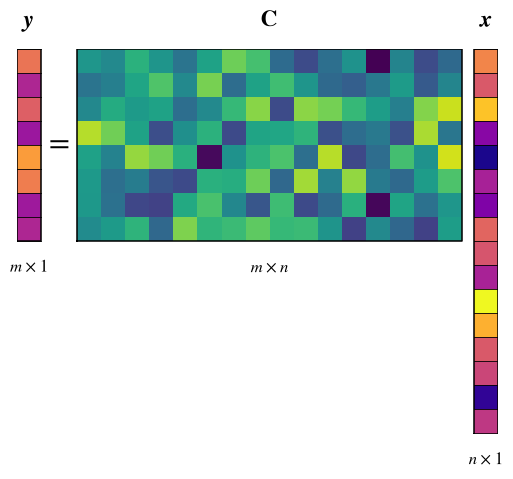

In [8]:
save_dual(plot_block_dense, 'cs_block_dense', FIG)
plt.show()

**How to read this figure.** Picture (c) uses the same $\mathbf{C}$ but the
dense signal $\boldsymbol{x}=\boldsymbol{\Psi}\boldsymbol{s}$: all 16 cells
are coloured. $\boldsymbol{y}$ again has 8 coloured cells.

**What it shows.** Now there is no blank cell anywhere and no visible
structure to exploit. Taken at face value this is an 8-by-16 system with 16
genuine unknowns, and it cannot be solved.

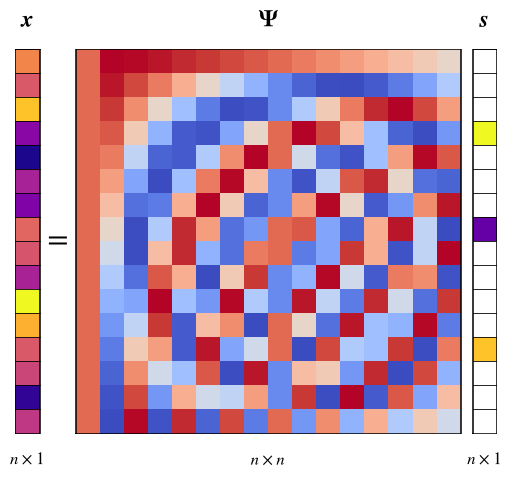

In [9]:
save_dual(plot_block_basis, 'cs_block_basis', FIG)
plt.show()

**How to read this figure.** Picture (d) is the change of basis
$\boldsymbol{x}=\boldsymbol{\Psi}\boldsymbol{s}$. Left: the same dense
$\boldsymbol{x}$ ($16\times1$). Middle: $\boldsymbol{\Psi}$ ($16\times16$),
one DCT basis vector per column; the first column is constant and the
columns oscillate faster from left to right. Right: $\boldsymbol{s}$
($16\times1$) with only 3 coloured cells (indices 3, 7 and 12, counting from
0 at the top).

**What it shows.** The dense signal is just a weighted sum of 3 columns of
$\boldsymbol{\Psi}$. The sparsity was there all along, hidden by the choice
of basis. Writing the unknown as $\boldsymbol{s}$ restores the prior that
picture (c) seemed to lose.

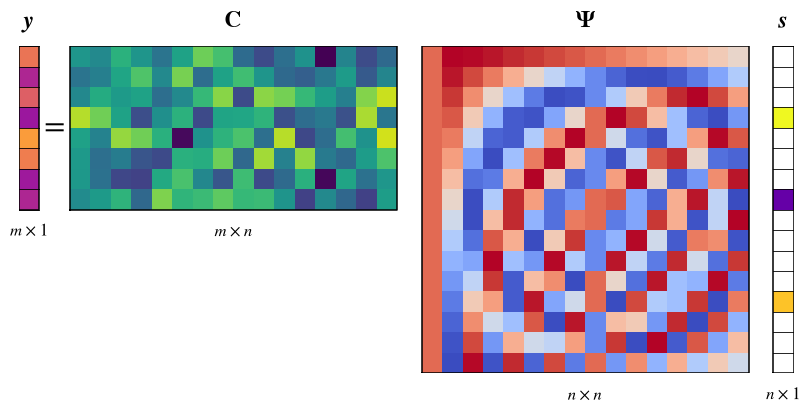

In [10]:
save_dual(plot_block_chain, 'cs_block_chain', FIG)
plt.show()

**How to read this figure.** Picture (e) substitutes (d) into (c):
$\boldsymbol{y}$ ($8\times1$) equals $\mathbf{C}$ ($8\times16$) times
$\boldsymbol{\Psi}$ ($16\times16$) times $\boldsymbol{s}$ ($16\times1$). The
colours of each block are the same as in the earlier pictures.

**What it shows.** Measurement and representation are two separate
matrices in a chain. The unknown on the right is now the sparse
$\boldsymbol{s}$, not the dense $\boldsymbol{x}$.

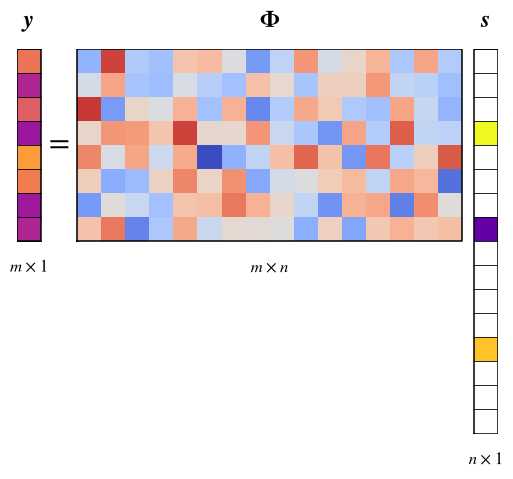

In [11]:
save_dual(plot_block_phi, 'cs_block_phi', FIG)
plt.show()

**How to read this figure.** Picture (f) multiplies the two matrices into
$\boldsymbol{\Phi}=\mathbf{C}\boldsymbol{\Psi}$ ($8\times16$, red positive,
blue negative). $\boldsymbol{y}$ and $\boldsymbol{s}$ are unchanged from (e).

**What it shows.** The picture has the same shape as (b): a short
$\boldsymbol{y}$, a wide matrix, and a long vector with only 3 coloured
cells. The dense problem has become a sparse one with sensing matrix
$\boldsymbol{\Phi}$. $\boldsymbol{\Phi}$ looks just as unstructured as
$\mathbf{C}$, which is what we want: every measurement still sees every
coefficient.

**Recap of the six pictures.** Read them in order. In (b) the system has 8 equations and 16
unknowns but only 3 of the unknowns are nonzero; a sparse $\boldsymbol{x}$
is the case compressed sensing can handle directly. In (c) every entry of
$\boldsymbol{x}$ is occupied and no prior is left. (d) restores one: the
*same* dense $\boldsymbol{x}$ is three DCT atoms. (e)–(f) fold the basis into
the measurement, $\boldsymbol{\Phi}=\mathbf{C}\boldsymbol{\Psi}$, and we are
back to picture (b) with $\boldsymbol{s}$ as the sparse unknown.

## 4. A 1-D signal in Fourier space

Three tones, $n=256$ samples. Every time sample is nonzero; in the Fourier
basis ($\boldsymbol{\Psi}$ = unitary inverse DFT) only $2\times3=6$ of the
256 coefficients are (each real tone is a $\pm f$ pair). Keeping the largest
5% reconstructs the signal exactly.

In the cell below:

* $\boldsymbol{x}$ = `x1`, $x(t)=\sum_j a_j\sin(2\pi f_j t)$ for the
  (frequency $f_j$, amplitude $a_j$) pairs in `TONES`, sampled at
  $t=0,1/256,\dots$ on $[0,1)$;
* `PSI1` $=\boldsymbol{\Psi}$, the $256\times256$ unitary inverse DFT matrix
  (complex valued), and `s1` $=\boldsymbol{s}$, the unitary FFT of
  $\boldsymbol{x}$, so that $\boldsymbol{x}=\boldsymbol{\Psi}\boldsymbol{s}$;
* `k1` is the number of coefficients kept ($5\%$ of 256, rounded), `thr` the
  magnitude of the `k1`-th largest coefficient, and `x1_rec` the signal
  rebuilt from the kept coefficients only;
* `err1` is the relative error
  $\|\hat{\boldsymbol{x}}-\boldsymbol{x}\|_2/\|\boldsymbol{x}\|_2$.

In [12]:
t = np.arange(N_SIG) / N_SIG
x1 = sum(a * np.sin(2 * np.pi * f * t) for f, a in TONES)
PSI1 = np.fft.ifft(np.eye(N_SIG), norm='ortho', axis=0)    # x = PSI1 @ s
s1 = np.fft.fft(x1, norm='ortho')
assert np.allclose(PSI1 @ s1, x1)

k1 = int(round(KEEP_1D * N_SIG))
thr = np.sort(np.abs(s1))[::-1][k1 - 1]                    # magnitude of the k1-th largest coefficient
s1_keep = np.where(np.abs(s1) >= thr, s1, 0)
x1_rec = np.real(PSI1 @ s1_keep)                           # imaginary part is round-off only
nnz1 = int(np.sum(np.abs(s1) > 1e-8 * np.abs(s1).max()))
err1 = np.linalg.norm(x1_rec - x1) / np.linalg.norm(x1)
print(f"1-D: nonzero Fourier coefficients {nnz1}/{N_SIG}; keep {k1} -> rel. error {err1:.2e}")
assert nnz1 == 2 * len(TONES), "each real tone is exactly one +/- frequency pair"
assert err1 < 1e-12, "keeping 5% must reconstruct the three-tone signal exactly"

1-D: nonzero Fourier coefficients 6/256; keep 13 -> rel. error 1.62e-15


Only 6 of the 256 Fourier coefficients are nonzero. Keeping the largest 13
(5%) therefore keeps all six, and the relative error is $1.62\times10^{-15}$,
which is round-off: the reconstruction is exact.

The next cell plots the signal, its spectrum and the reconstruction.

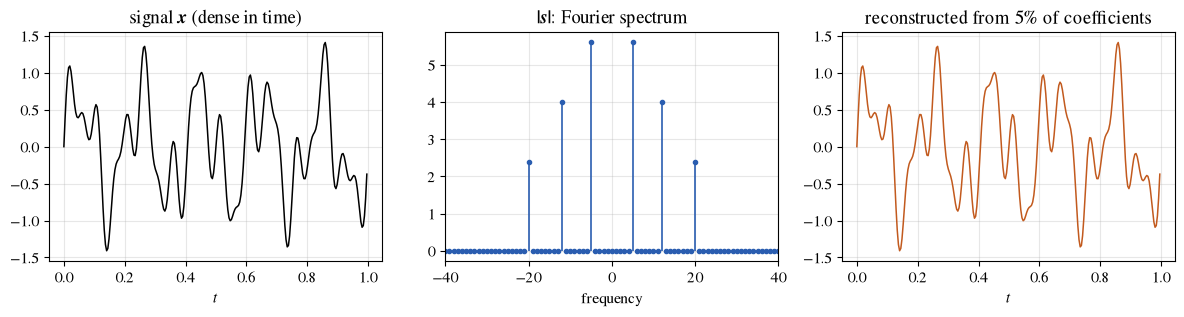

In [13]:
def plot_fourier_1d():
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
    ax[0].plot(t, x1, color=fg(), lw=1.1)
    ax[0].set(title=r'signal $\boldsymbol{x}$ (dense in time)', xlabel='$t$')
    freqs = np.fft.fftshift(np.fft.fftfreq(N_SIG, d=1 / N_SIG))
    mk, st, bl = ax[1].stem(freqs, np.abs(np.fft.fftshift(s1)), basefmt=' ')
    plt.setp(st, color='C0', lw=1.2); plt.setp(mk, color='C0', ms=3)
    ax[1].set(title=r'$|\boldsymbol{s}|$: Fourier spectrum', xlabel='frequency', xlim=(-40, 40))
    ax[2].plot(t, x1_rec, color='C1', lw=1.1)
    ax[2].set(title=f'reconstructed from {100 * KEEP_1D:.0f}% of coefficients', xlabel='$t$')
    plt.tight_layout()


save_dual(plot_fourier_1d, 'cs_fourier_1d', FIG)
plt.show()

**How to read this figure.** Left: the signal $\boldsymbol{x}$ against time
$t$ on $[0,1)$. Middle: the magnitudes $|s|$ of all Fourier coefficients as
stems, against frequency, shown from $-40$ to $40$ (negative and positive
frequencies, zero in the middle). Right: the signal rebuilt from the kept
5% of coefficients, against $t$.

**What it shows.** The waveform looks irregular and every sample is
nonzero. The spectrum has exactly six stems, at $\pm5$, $\pm12$ and $\pm20$,
with heights in the ratio of the amplitudes 0.7, 0.5 and 0.3; every other
stem is zero. The reconstructed curve is the same as the original, as the
printed error of $1.62\times10^{-15}$ says.

The same statement as a matrix picture, now at full size: the column
$\boldsymbol{x}$, the $256\times256$ basis $\boldsymbol{\Psi}$ (real part),
and the support of $\boldsymbol{s}$ (highlighted cells are the kept
coefficients).

`strip_triplet` draws three panels side by side: a vector as a grey column,
a basis matrix in `coolwarm`, and the kept positions of the coefficient
vector as red cells on a blank column. It is reused for the image in
section 5.

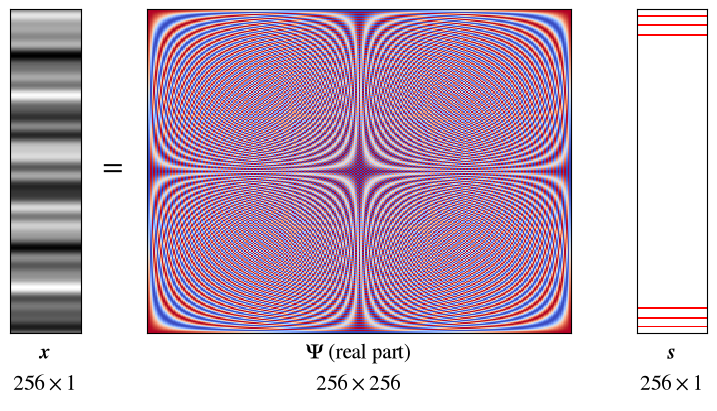

In [14]:
def strip_triplet(xvec, Psi, support, xlabel, psilabel, slabel):
    nn = len(xvec)
    fig, ax = plt.subplots(1, 3, figsize=(9, 4.2),
                           gridspec_kw=dict(width_ratios=[1, 6, 1], wspace=0.35))
    ax[0].imshow(xvec.reshape(nn, 1), cmap='gray', aspect='auto', interpolation='nearest')
    ax[1].imshow(np.real(Psi), cmap=BASIS_CMAP, aspect='auto', interpolation='nearest')
    sup = np.ma.masked_where(~support, np.ones(nn))
    ax[2].imshow(np.zeros((nn, 1)), cmap='gray', vmin=0, vmax=1, alpha=0.0, aspect='auto')
    ax[2].imshow(sup.reshape(nn, 1), cmap='autumn', aspect='auto', interpolation='nearest')
    for a, lbl in zip(ax, [xlabel, psilabel, slabel]):
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
        for sp in a.spines.values():
            sp.set_color(fg())
        a.set_xlabel(lbl, fontsize=15)
    eq_x = (ax[0].get_position().x1 + ax[1].get_position().x0) / 2
    fig.text(eq_x, 0.5, '$=$', fontsize=22, ha='center', va='center')


def plot_fourier_1d_matrices():
    nonzero = np.abs(s1) > 1e-8 * np.abs(s1).max()          # the 6 true tone coefficients
    strip_triplet(x1, PSI1, nonzero,
                  f'$\\boldsymbol{{x}}$\n${N_SIG}\\times1$',
                  f'$\\boldsymbol{{\\Psi}}$ (real part)\n${N_SIG}\\times{N_SIG}$',
                  f'$\\boldsymbol{{s}}$\n${N_SIG}\\times1$')


save_dual(plot_fourier_1d_matrices, 'cs_fourier_1d_matrices', FIG)
plt.show()

**How to read this figure.** Left: $\boldsymbol{x}$ ($256\times1$) as a
column of grey levels, top to bottom in time (dark is negative, light is
positive). Middle: the real part of $\boldsymbol{\Psi}$ ($256\times256$);
each column is a cosine at one frequency, red positive and blue negative.
The left half holds frequencies $0$ to $127$, the right half the negative
frequencies, which is why the pattern is mirrored about the centre. Right:
$\boldsymbol{s}$ ($256\times1$); a red cell marks a nonzero coefficient
and white means exactly zero (below $10^{-8}$ of the largest).

**What it shows.** Exactly 6 of the 256 cells of $\boldsymbol{s}$ are red:
the three tones at 5, 12 and 20 Hz near the top and their negative-frequency
partners near the bottom. Only 6 of the 256 columns of
$\boldsymbol{\Psi}$ are needed. A long dense column equals a big matrix
times an almost empty vector.

## 5. An image in Fourier space

Images are not exactly sparse, but they are *compressible*: the sorted
Fourier magnitudes fall off fast. Keeping the largest 20% of the 2-D Fourier
coefficients of the $128\times128$ portrait keeps the picture.

For an image the basis acts on the vectorised pixels: with $\mathbf{F}$ the
1-D unitary DFT, the 2-D DFT basis is the Kronecker product
$\boldsymbol{\Psi}=\mathbf{F}^{-1}\otimes\mathbf{F}^{-1}$. We draw it for a
$32\times32$ version of the image ($n=1024$); at $128^2$ it would have
$2.7\times10^{8}$ entries.

The cell below:

* loads the portrait and defines `load(side)`, which resizes it to
  `side` $\times$ `side` pixels with values in $[0,1]$;
* defines `keep_top(S, frac)`, which keeps the largest fraction `frac` of
  the coefficients by magnitude and zeros the rest;
* for the $128\times128$ image computes the 2-D FFT `S2`, keeps 20%
  (`S2_keep`), inverts to `img_rec`, and reports the relative error `err2`
  and the PSNR, $10\log_{10}(1/\mathrm{MSE})$ in dB (MSE is the mean squared
  pixel error; higher PSNR is better);
* for the $32\times32$ image `img_s` builds the full basis matrix `PSI2` with
  a Kronecker product and the coefficients `s2`. The image is vectorised
  column by column (`order='F'`). The asserts check that multiplying by
  this matrix gives the same numbers as the fast 2-D FFT.

In [15]:
portrait = np.asarray(Image.open(os.path.join(DATA, 'portrait.png')).convert('L'), float) / 255.0


def load(side):
    """The portrait resized to side x side pixels, values in [0, 1]."""
    return np.asarray(Image.fromarray((portrait * 255).astype(np.uint8))
                      .resize((side, side), Image.LANCZOS), float) / 255.0


def keep_top(S, frac):
    """Zero all but the largest `frac` fraction of coefficients (by magnitude)."""
    k = max(1, int(round(frac * S.size)))
    thr = np.sort(np.abs(S).ravel())[::-1][k - 1]
    return np.where(np.abs(S) >= thr, S, 0)


img = load(SIDE_IMG)
S2 = np.fft.fft2(img, norm='ortho')
S2_keep = keep_top(S2, KEEP_2D)
img_rec = np.real(np.fft.ifft2(S2_keep, norm='ortho'))
err2 = np.linalg.norm(img_rec - img) / np.linalg.norm(img)
psnr2 = 10 * np.log10(1.0 / np.mean((img_rec - img) ** 2))
print(f"2-D: keep {100 * KEEP_2D:.0f}% of {img.size} coefficients -> rel. error {err2:.4f}, PSNR {psnr2:.1f} dB")
assert err2 < 0.08 and psnr2 > 28, "20% of the Fourier coefficients must keep the portrait (rel. err < 8%, PSNR > 28 dB)"

# the drawable 2-D basis (n = SIDE_PSI^2)
img_s = load(SIDE_PSI)
F1 = np.fft.ifft(np.eye(SIDE_PSI), norm='ortho', axis=0)
PSI2 = np.kron(F1, F1)                                  # 1024 x 1024 2-D inverse DFT
s2 = np.conj(PSI2).T @ img_s.ravel(order='F')          # s = Psi^H x (Psi is unitary)
assert np.allclose(np.fft.fft2(img_s, norm='ortho').ravel(order='F'), s2), "Kronecker basis == 2-D FFT"
assert np.allclose(np.real(PSI2 @ s2), img_s.ravel(order='F'))
s2_keep = keep_top(s2, KEEP_2D)
print(f"drawable basis: n = {img_s.size}, Psi is {PSI2.shape[0]}x{PSI2.shape[1]}, "
      f"keep {np.count_nonzero(s2_keep)} of {s2.size} coefficients")

2-D: keep 20% of 16384 coefficients -> rel. error 0.0589, PSNR 30.4 dB
drawable basis: n = 1024, Psi is 1024x1024, keep 205 of 1024 coefficients


Keeping 20% of the 16384 Fourier coefficients of the $128\times128$
portrait gives a relative error of 0.0589 and a PSNR of 30.4 dB: the picture
survives with four fifths of its coefficients removed. For the small
$32\times32$ version the basis matrix is $1024\times1024$ and 205 of the 1024
coefficients are kept.

The next cell only defines the two plotting functions for this section.
They are drawn further down, after the picture-to-vector figure.

In [16]:
def plot_fourier_2d():
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.9))
    ax[0].imshow(img, cmap='gray', vmin=0, vmax=1)
    ax[0].set_title(f'original ({SIDE_IMG}$\\times${SIDE_IMG})')
    kept = np.abs(np.fft.fftshift(S2_keep))
    ax[1].imshow(np.zeros_like(kept), cmap='gray', vmin=0, vmax=1)
    ax[1].imshow(np.ma.masked_where(kept == 0, np.log10(kept + 1e-12)), cmap='magma')
    ax[1].set_title(f'top {100 * KEEP_2D:.0f}% Fourier coefficients')
    ax[2].imshow(np.clip(img_rec, 0, 1), cmap='gray', vmin=0, vmax=1)
    ax[2].set_title(f'reconstructed (rel. err {err2:.3f})')
    for a in ax:
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
    plt.tight_layout()


def plot_fourier_2d_matrices():
    n2 = SIDE_PSI ** 2
    strip_triplet(img_s.ravel(order='F'), PSI2, np.abs(s2_keep) > 0,
                  f'$\\boldsymbol{{x}}$\n${n2}\\times1$',
                  f'$\\boldsymbol{{\\Psi}}=\\mathbf{{F}}^{{-1}}\\otimes\\mathbf{{F}}^{{-1}}$\n${n2}\\times{n2}$',
                  f'$\\boldsymbol{{s}}$\n${n2}\\times1$')

### From the picture to the vector, and back

The column $\boldsymbol{x}$ above *is* the $32\times32$ portrait: stack its
32 pixel columns on top of each other and you get $n=1024$ numbers. The
coefficient vector $\boldsymbol{s}$ has the same length, and reshaping it
back to $32\times32$ gives the image's 2-D spectrum.

The cell below draws five panels connected by arrows: the image, the
stacked column $\boldsymbol{x}$, the basis $\boldsymbol{\Psi}$, the
coefficient column $\boldsymbol{s}$, and $\boldsymbol{s}$ reshaped to a
square.

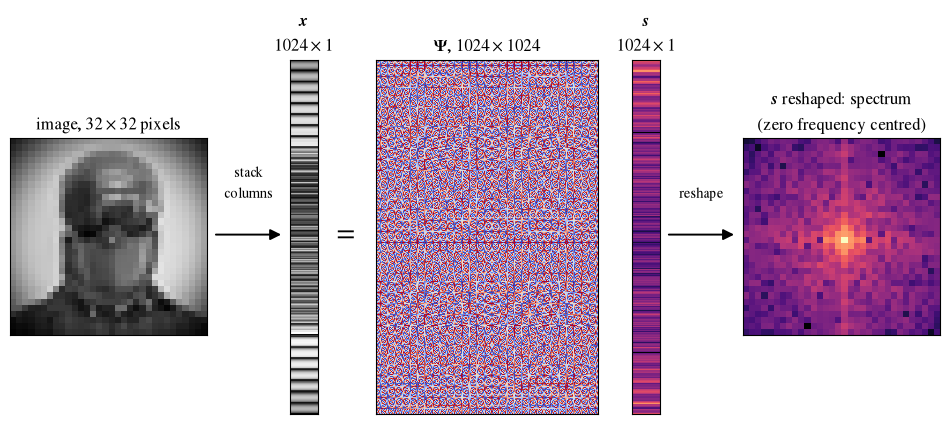

In [17]:
def plot_image_to_vector():
    S2s = np.fft.fft2(img_s, norm='ortho')
    n2 = SIDE_PSI ** 2
    fig = plt.figure(figsize=(12, 4.6))
    gs = fig.add_gridspec(1, 9, width_ratios=[3.2, 0.9, 0.45, 0.5, 3.6, 0.12, 0.45, 0.9, 3.2], wspace=0.15)
    a_img = fig.add_subplot(gs[0]); a_x = fig.add_subplot(gs[2]); a_psi = fig.add_subplot(gs[4])
    a_s = fig.add_subplot(gs[6]); a_spec = fig.add_subplot(gs[8])
    a_img.imshow(img_s, cmap='gray', vmin=0, vmax=1)
    a_img.set_title(f'image, ${SIDE_PSI}\\times{SIDE_PSI}$ pixels', fontsize=12)
    a_x.imshow(img_s.ravel(order='F')[:, None], cmap='gray', aspect='auto', interpolation='nearest')
    a_x.set_title(f'$\\boldsymbol{{x}}$\n${n2}\\times1$', fontsize=12)
    a_psi.imshow(np.real(PSI2), cmap=BASIS_CMAP, aspect='auto', interpolation='nearest')
    a_psi.set_title(f'$\\boldsymbol{{\\Psi}}$, ${n2}\\times{n2}$', fontsize=12)
    lm = np.log10(np.abs(S2s.ravel(order='F')) + 1e-6)
    a_s.imshow(lm[:, None], cmap='magma', aspect='auto', interpolation='nearest')
    a_s.set_title(f'$\\boldsymbol{{s}}$\n${n2}\\times1$', fontsize=12)
    a_spec.imshow(np.log10(np.abs(np.fft.fftshift(S2s)) + 1e-6), cmap='magma')
    a_spec.set_title('$\\boldsymbol{s}$ reshaped: spectrum\n(zero frequency centred)', fontsize=12)
    for a in [a_img, a_x, a_psi, a_s, a_spec]:
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
        for sp in a.spines.values():
            sp.set_color(fg())
    def arrow(ax_from, ax_to, text):
        b0, b1 = ax_from.get_position(), ax_to.get_position()
        fig.patches.append(plt.matplotlib.patches.FancyArrowPatch(
            (b0.x1 + 0.005, 0.5), (b1.x0 - 0.005, 0.5), transform=fig.transFigure,
            arrowstyle='-|>', mutation_scale=16, color=fg(), lw=1.4))
        fig.text((b0.x1 + b1.x0) / 2, 0.58, text, ha='center', fontsize=10)
    arrow(a_img, a_x, 'stack\ncolumns')
    arrow(a_s, a_spec, 'reshape')
    eq = (a_x.get_position().x1 + a_psi.get_position().x0) / 2
    fig.text(eq, 0.5, '$=$', fontsize=20, ha='center', va='center')


save_dual(plot_image_to_vector, 'cs_image_to_vector', FIG)
plt.show()

**How to read this figure.** From left to right: the $32\times32$ portrait;
the arrow "stack columns" turns it into $\boldsymbol{x}$, a $1024\times1$
column of grey levels (dark pixels dark, bright pixels bright); the "$=$"
sign and $\boldsymbol{\Psi}$, the $1024\times1024$ 2-D Fourier basis (real
part, red positive, blue negative); $\boldsymbol{s}$, the $1024\times1$
coefficient column coloured by $\log_{10}|s|$ (bright means large, dark means
small); and the arrow "reshape" back to a $32\times32$ square, shifted so
that zero frequency is in the centre.

**What it shows.** An image is just a long vector, so everything said about
$\boldsymbol{y}=\mathbf{C}\boldsymbol{\Psi}\boldsymbol{s}$ applies to images
unchanged. The coefficient column looks busy, but reshaped into a square it
has a clear structure: a bright centre (low spatial frequencies, smooth
variations) that fades toward the edges (fine detail). Most of the
coefficients are small.

Now the compression itself, on the $128\times128$ portrait.

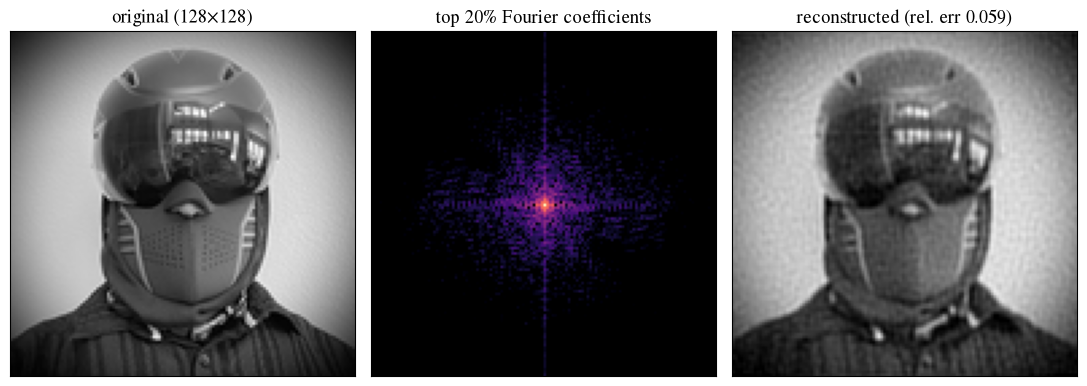

In [18]:
save_dual(plot_fourier_2d, 'cs_fourier_2d', FIG)
plt.show()

**How to read this figure.** Left: the original $128\times128$ portrait.
Middle: the 2-D Fourier plane with zero frequency in the centre; coloured
pixels are the 20% of coefficients that were kept, coloured by
$\log_{10}$ of their magnitude (bright is large), and black pixels were
discarded. Right: the image rebuilt from the kept coefficients only, with
its relative error in the title.

**What it shows.** The kept coefficients form a cloud around the centre,
with a cross along the axes that comes from horizontal and vertical edges
in the picture. The large high-frequency region is black: it was thrown
away. The reconstruction (relative error 0.059, PSNR 30.4 dB) keeps the
face, helmet and visor; only fine texture is softened and a faint ringing
appears near sharp edges. The image is not sparse, but it is compressible.

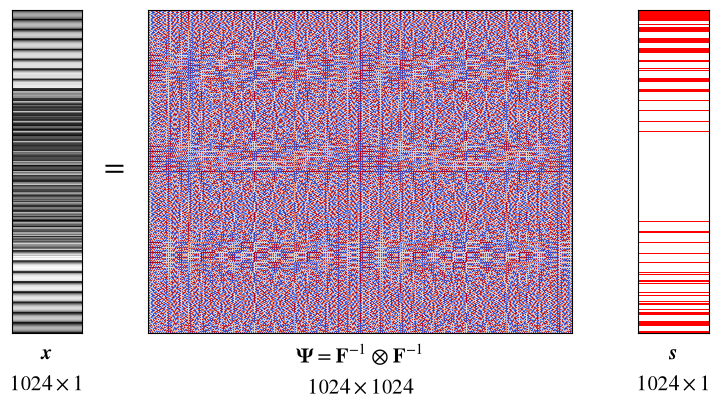

In [19]:
save_dual(plot_fourier_2d_matrices, 'cs_fourier_2d_matrices', FIG)
plt.show()

**How to read this figure.** The same three-panel layout as the 1-D matrix
picture, now for the $32\times32$ image. Left: $\boldsymbol{x}$
($1024\times1$), the stacked pixel columns in grey. Middle:
$\boldsymbol{\Psi}=\mathbf{F}^{-1}\otimes\mathbf{F}^{-1}$ ($1024\times1024$,
real part, red positive, blue negative). Right: $\boldsymbol{s}$
($1024\times1$); red cells are the 205 kept coefficients, white cells were
discarded.

**What it shows.** Unlike the three-tone signal, the image needs many
coefficients, but they are far from uniformly spread. Because the image is
stacked column by column, the first and last blocks of $\boldsymbol{s}$ hold
the low horizontal frequencies (positive at the top, negative at the
bottom), and that is where the red cells cluster. The middle of the column,
the highest horizontal frequencies, is almost empty. The Kronecker
structure of $\boldsymbol{\Psi}$ is visible as a faint grid of $32\times32$
blocks.

## Summary

* $\boldsymbol{y}=\mathbf{C}\boldsymbol{x}$ with $m<n$ (here 8 equations, 16
  unknowns) is hopeless without a prior. Sparsity of $\boldsymbol{x}$, or of
  its coefficients $\boldsymbol{s}$ in a basis $\boldsymbol{\Psi}$, is that
  prior.
* The change of unknown $\boldsymbol{x}=\boldsymbol{\Psi}\boldsymbol{s}$ turns
  a dense problem into a sparse one with sensing matrix
  $\boldsymbol{\Phi}=\mathbf{C}\boldsymbol{\Psi}$.
* A three-tone signal is exactly 6-sparse in Fourier (6 of 256
  coefficients); keeping 5% rebuilds it to round-off.
* An image is merely *compressible*: keeping 20% of its 2-D Fourier
  coefficients gives a relative error of 0.0589 (30.4 dB). Stacked into a
  vector, an image fits the same matrix pictures as a 1-D signal.

Next: `cs_regularization` (why $\ell_1$ finds sparse solutions). Later,
`cs_portrait_fista` actually solves for $\boldsymbol{s}$ from a random subset
of pixels.

## Try this

1. Set `SUPPORT = [0, 1, 2]` and rerun the six pictures. Expect the three
   coloured cells of $\boldsymbol{s}$ to move to the top, and $\boldsymbol{x}$
   in pictures (c) and (d) to vary slowly from top to bottom, because only
   the smoothest DCT basis vectors are used.
2. Set `M_TOY = 16, 4` (keep $n=16$, use $m=4$). Expect $\boldsymbol{y}$,
   $\mathbf{C}$ and $\boldsymbol{\Phi}$ to shrink to 4 rows while
   $\boldsymbol{s}$ still has 3 nonzeros: 4 equations for 3 unknown values at
   unknown positions is close to the limit of what can work.
3. Add a fourth tone, `TONES = [(5, 0.7), (12, 0.5), (20, 0.3), (30, 0.2)]`.
   Expect 8 nonzero Fourier coefficients instead of 6; 13 kept coefficients
   still cover them, so the reconstruction stays exact. Then set
   `KEEP_1D = 0.015` with the original three tones: only 4 coefficients are
   kept, the 20 Hz pair is lost, the error is no longer at round-off, and the
   assert fails.
4. Set `KEEP_2D = 0.05`. Expect a visibly blurrier reconstruction, a larger
   relative error and a lower PSNR, and the assert (rel. err below 0.08,
   PSNR above 28 dB) to fail.